In [1]:
%config InlineBackend.figure_format = 'svg'

import matplotlib.pyplot as plt

# Path points in the world frame
from data.paths import path_1, path_2

# Import pose and frame transformation helper functions
from utilities.pose_functions import *

In [2]:
# Updatable pose parameters of the robot in the world frame
robot_position = np.array([1, 1])
robot_heading = 0.0 * np.pi

# Static parameters of the robot
wheelbase = 0.36
look_ahead_distance = 1

In [3]:
x = path_2[:, 0]
y = path_2[:, 1]

In [4]:
def find_intersect_tuple():
    """Returns the two points that create an intersecting line with the look ahead circle in the forward direction."""

    # Initialize the comparison parameters
    position_difference = robot_position - path_1[0]
    initial_rear_axel_distance = np.sqrt(np.dot(position_difference, position_difference))
    was_smaller = initial_rear_axel_distance < look_ahead_distance

    # Loop over the rest of the points
    for i in range(1, len(path_1)):
        position_difference = robot_position - path_1[i]
        rear_axel_distance = np.sqrt(np.dot(position_difference, position_difference))

        # Check if point is within look ahead circle
        if rear_axel_distance < look_ahead_distance:
            was_smaller = True

        # Check if point is outside the look ahead circle
        if rear_axel_distance > look_ahead_distance:
            if was_smaller == True:
                # Return the intersecting tuple (previous point (inside) and point that just exceeded look ahead distance
                return path_1[i-1], path_1[i]
            else:
                # Think about if we should handle this a specific way...
                pass

    # Maybe perform additional checks or potentially iterative function calls (with larger look ahead distances)
    # here to ensure that a point for navigation (pursuit) can be found.
    raise ValueError("Couldn't find an intersection tuple.")

In [5]:
def plot_circle(center: Tuple[float, float] | NDArray, radius: float, color: str = 'black') -> None:
    rads = np.linspace(0, 2 * np.pi, 100)
    x_ = radius * np.cos(rads) + center[0]
    y_ = radius * np.sin(rads) + center[1]
    plt.plot(x_, y_, ls='--', color=color, alpha=0.3)

In [6]:
def plot_car(rear_axel_position: Tuple[float, float] | NDArray, vehicle_orientation: float) -> None:
    front_axel_position = rear_axel_position + wheelbase * np.array([np.cos(vehicle_orientation), np.sin(vehicle_orientation)])
    plt.plot([rear_axel_position[0], front_axel_position[0]], [rear_axel_position[1], front_axel_position[1]], c='r')

In [7]:
intersect_candidate_1, intersect_candidate_2 = find_intersect_tuple()
intersect_candidates_x = [intersect_candidate_1[0], intersect_candidate_2[0]]
intersect_candidates_y = [intersect_candidate_1[1], intersect_candidate_2[1]]

print(intersect_candidate_1, intersect_candidate_2)

[1.63459936 0.33832691] [1.75147701 0.31306789]


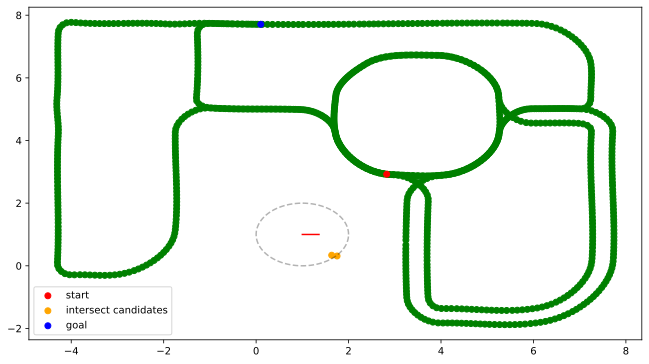

In [8]:
plt.figure(figsize=(11, 6), dpi=200)

plt.scatter(x, y, c='g')
plt.scatter(x[0], y[0], c='r', label='start')

plt.scatter(intersect_candidates_x, intersect_candidates_y, c='orange', label='intersect candidates')

plot_car(robot_position, robot_heading)
plot_circle(robot_position, look_ahead_distance)

plt.scatter(x[-1], y[-1], c='blue', label='goal')

plt.legend()
plt.show()

In [9]:
# Create the robots pose in the world frame
robot_pose = make_pose(robot_position[0], robot_position[1], robot_heading)

# Invert the pose to get the transformation from the world frame to the robots frame
world_to_robot = invert_pose(robot_pose)

# Compute the intersect points in the robots frame
intersects_robot_frame = transform_points(world_to_robot, np.array([intersect_candidate_1, intersect_candidate_2]))

# Print as verification helper
print(intersects_robot_frame)

[[ 0.63459936 -0.66167309]
 [ 0.75147701 -0.68693211]]


In [10]:
# Compute the intersection point in the robots frame
def get_eta(x_0, x_1, c, l_1):
    d = x_1 - x_0
    r = x_0 - c

    square_root = np.sqrt(np.dot(r, d) ** 2 - np.dot(d, d) * (np.dot(r, r) - l_1 ** 2))

    t_1 = (-np.dot(r, d) + square_root) / np.dot(d, d)
    t_2 = (-np.dot(r, d) - square_root) / np.dot(d, d)

    phi_1 = np.arctan2(r[1] + t_1 * d[1], r[0] + t_1 * d[0])
    phi_2 = np.arctan2(r[1] + t_2 * d[1], r[0] + t_2 * d[0])

    return phi_1, phi_2

phis = get_eta(intersects_robot_frame[0], intersects_robot_frame[1], np.array([0, 0]), look_ahead_distance)
print(phis)

phi_1 = phis[0]

(np.float64(-0.7511572068682011), np.float64(-2.816118793843666))


In [11]:
def get_eta_revised(x_0, x_1, l_1):
    """Return the target angle in the car frame.

    x_0 and x_1 are NumPy arrays of shape (2,).
    x_0 must be strictly inside the lookahead circle,
    and x_1 strictly outside.
    """
    if l_1 <= 0:
        raise ValueError("Lookahead distance must be positive.")

    radius_squared = l_1 * l_1
    start_squared = np.dot(x_0, x_0)
    end_squared = np.dot(x_1, x_1)

    if not (start_squared < radius_squared < end_squared):
        raise ValueError("Expected an inside endpoint followed by an outside endpoint.")

    d = x_1 - x_0

    a = np.dot(d, d)
    b = np.dot(x_0, d)
    q = start_squared - radius_squared

    t = (-b + np.sqrt(b * b - a * q)) / a
    intersection = x_0 + t * d

    return float(np.arctan2(intersection[1], intersection[0]))

In [12]:
intersect_point = look_ahead_distance * np.array([np.cos(phi_1), np.sin(phi_1)])
print(intersect_point)

intersect_point_in_world = (robot_pose @ get_translation_vector(intersect_point))[:2]
print(intersect_point_in_world)

[ 0.73089958 -0.68248502]
[1.73089958 0.31751498]


In [13]:
def from_to(start, end):
    return start[0], start[1], end[0] - start[0], end[1] - start[1]

In [14]:
def get_steering_angle(eta: float) -> float:
    return np.arctan(2 * wheelbase * np.sin(eta) / look_ahead_distance)

sa = get_steering_angle(phi_1)

print(sa * 180 / np.pi, "degrees")

-26.169003974525154 degrees


In [15]:
def get_steering_radius(eta: float) -> float:
    return abs(look_ahead_distance / (2 * np.sin(eta)))

r = get_steering_radius(phi_1)
print(r)

0.7326168138691571


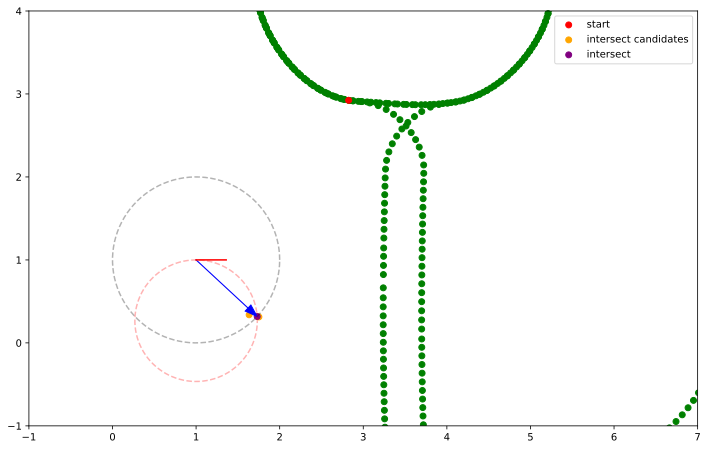

In [16]:
plt.figure(figsize=(12, 7.5), dpi=200)

plt.scatter(x, y, c='g')
plt.scatter(x[0], y[0], c='r', label='start')

plt.scatter(intersect_candidates_x, intersect_candidates_y, c='orange', label='intersect candidates')

plt.scatter(intersect_point_in_world[0], intersect_point_in_world[1], c='purple', label='intersect')

plot_car(robot_position, robot_heading)
plot_circle(robot_position, look_ahead_distance)

plot_circle(robot_position - np.array([0, r]), r, color='red')

plt.arrow(*from_to(robot_position, intersect_point_in_world), head_width=0.1, length_includes_head=True, color="blue")

plt.xlim(-1, 7)
plt.ylim(-1, 4)
plt.legend()
plt.show()